# Day 6: Uber Eats Business Insights and Project Integration

## Objective

The objective of this phase is to integrate the outputs from the previous project days and convert the analytical findings into actionable business recommendations.

The analysis covers:

1. Customer and restaurant segmentation.
2. Customer review sentiment analysis.
3. Delivery-time prediction.
4. Hourly order demand forecasting.
5. Business KPI summaries and recommendations.
6. Project limitations and future improvements.

**Tools:** Python, Pandas, Matplotlib, and previously trained machine-learning and forecasting models.

**Note:** The project uses synthetic data. The results demonstrate an analytical workflow and should not be interpreted as actual Uber Eats business performance.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "data" / "raw").exists():
    PROJECT_DIR = Path.home() / "Projects" / "uber-eats-intelligence"

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
FIGURES_DIR = PROJECT_DIR / "reports" / "figures"
INSIGHTS_DIR = PROJECT_DIR / "reports" / "insights"
MODELS_DIR = PROJECT_DIR / "models"

for folder in [PROCESSED_DIR, FIGURES_DIR, INSIGHTS_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)

Project directory: /home/nineleaps/Projects/uber-eats-intelligence


## Reviewing Existing Project Deliverables

Before combining the results, we need to verify which datasets, reports, and model outputs were saved during the previous phases.

This check helps us identify missing files without assuming that every notebook has completed successfully.

In [2]:
expected_files = [
    "data/raw/orders.csv",
    "data/raw/customers.csv",
    "data/raw/restaurants.csv",
    "data/raw/deliveries.csv",
    "data/raw/reviews.csv",
    "data/processed/customer_features.csv",
    "data/processed/restaurant_features.csv",
    "data/processed/cleaned_reviews.csv",
    "data/processed/hourly_order_demand.csv",
    "data/processed/delivery_time_predictions.csv",
    "data/processed/hourly_demand_forecasts.csv",
    "reports/insights/customer_cluster_profiles.csv",
    "reports/insights/restaurant_cluster_profiles.csv",
    "reports/insights/sentiment_evaluation_metrics.csv",
    "reports/insights/regression_model_comparison.csv",
    "reports/insights/forecast_model_comparison.csv"
]

file_check = pd.DataFrame({
    "file": expected_files,
    "status": [
        "FOUND" if (PROJECT_DIR / file).exists() else "MISSING"
        for file in expected_files
    ]
})

print(file_check.to_string(index=False))

                                             file status
                              data/raw/orders.csv  FOUND
                           data/raw/customers.csv  FOUND
                         data/raw/restaurants.csv  FOUND
                          data/raw/deliveries.csv  FOUND
                             data/raw/reviews.csv  FOUND
             data/processed/customer_features.csv  FOUND
           data/processed/restaurant_features.csv  FOUND
               data/processed/cleaned_reviews.csv  FOUND
           data/processed/hourly_order_demand.csv  FOUND
     data/processed/delivery_time_predictions.csv  FOUND
       data/processed/hourly_demand_forecasts.csv  FOUND
   reports/insights/customer_cluster_profiles.csv  FOUND
 reports/insights/restaurant_cluster_profiles.csv  FOUND
reports/insights/sentiment_evaluation_metrics.csv  FOUND
 reports/insights/regression_model_comparison.csv  FOUND
   reports/insights/forecast_model_comparison.csv  FOUND


## Business KPI Analysis

Key Performance Indicators (KPIs) summarize business performance in a way that supports decision-making.

We will calculate total orders, completed orders, cancelled orders, cancellation rate, total payment amount, average delivery time, and sentiment distribution.

Revenue will be calculated from the payments dataset where available. These metrics describe the synthetic dataset, not actual business performance.

In [3]:
orders = pd.read_csv(RAW_DIR / "orders.csv")
deliveries = pd.read_csv(RAW_DIR / "deliveries.csv")
reviews = pd.read_csv(RAW_DIR / "reviews.csv")
payments = pd.read_csv(RAW_DIR / "payments.csv")
customers = pd.read_csv(RAW_DIR / "customers.csv")
restaurants = pd.read_csv(RAW_DIR / "restaurants.csv")

print("Orders:", orders.shape)
print("Deliveries:", deliveries.shape)
print("Reviews:", reviews.shape)
print("Payments:", payments.shape)
print("Customers:", customers.shape)
print("Restaurants:", restaurants.shape)

print("\nOrder statuses:")
print(orders["order_status"].value_counts())

Orders: (5000, 7)
Deliveries: (5000, 8)
Reviews: (3750, 6)
Payments: (5000, 5)
Customers: (500, 4)
Restaurants: (60, 5)

Order statuses:
order_status
Completed     4120
Cancelled      407
In Transit     280
Preparing      193
Name: count, dtype: int64


In [4]:
total_orders = orders["order_id"].nunique()

completed_orders = orders.loc[
    orders["order_status"].eq("Completed"), "order_id"
].nunique()

cancelled_orders = orders.loc[
    orders["order_status"].eq("Cancelled"), "order_id"
].nunique()

cancellation_rate = (
    cancelled_orders / total_orders * 100
    if total_orders else np.nan
)

delivery_times = pd.to_numeric(
    deliveries["delivery_time_minutes"],
    errors="coerce"
)

average_delivery_time = delivery_times[
    delivery_times > 0
].mean()

payment_amounts = pd.to_numeric(
    payments["total_amount"],
    errors="coerce"
)

total_payment_amount = payment_amounts.sum(min_count=1)

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Customers",
        "Total Restaurants",
        "Total Orders",
        "Completed Orders",
        "Cancelled Orders",
        "Cancellation Rate (%)",
        "Total Payment Amount",
        "Average Delivery Time (minutes)",
        "Total Reviews"
    ],
    "Value": [
        customers["customer_id"].nunique(),
        restaurants["restaurant_id"].nunique(),
        total_orders,
        completed_orders,
        cancelled_orders,
        cancellation_rate,
        total_payment_amount,
        average_delivery_time,
        reviews["review_id"].nunique()
    ]
})

print(kpi_summary.round(2).to_string(index=False))

kpi_summary.to_csv(
    INSIGHTS_DIR / "business_kpi_summary.csv",
    index=False
)

print("\nSaved business_kpi_summary.csv")

                            KPI      Value
                Total Customers     500.00
              Total Restaurants      60.00
                   Total Orders    5000.00
               Completed Orders    4120.00
               Cancelled Orders     407.00
          Cancellation Rate (%)       8.14
           Total Payment Amount 3807330.66
Average Delivery Time (minutes)      53.68
                  Total Reviews    3750.00

Saved business_kpi_summary.csv


## Customer Feedback Summary

Customer sentiment can help identify possible satisfaction issues. We will summarize the sentiment labels in the review dataset and calculate the percentage represented by each class.

Because the dataset's sentiment labels were synthetically generated, this describes the generated reviews rather than measured real-world customer satisfaction.

sentiment  review_count  percentage
 Positive          2076       55.36
 Negative           938       25.01
  Neutral           736       19.63


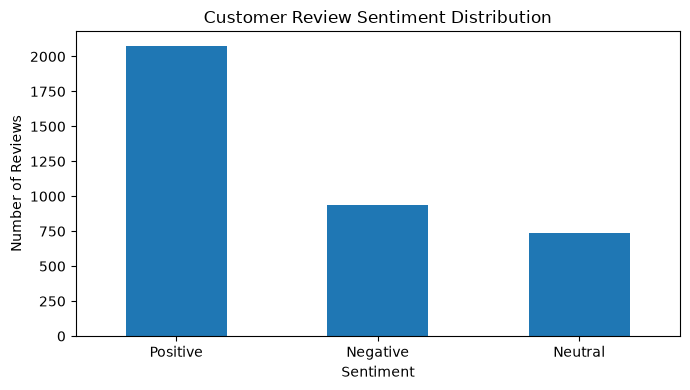

In [5]:
sentiment_counts = (
    reviews["sentiment_label"]
    .value_counts()
    .rename_axis("sentiment")
    .reset_index(name="review_count")
)

sentiment_counts["percentage"] = (
    sentiment_counts["review_count"]
    / sentiment_counts["review_count"].sum()
    * 100
)

print(sentiment_counts.round(2).to_string(index=False))

sentiment_counts.to_csv(
    INSIGHTS_DIR / "business_sentiment_summary.csv",
    index=False
)

sentiment_counts.plot(
    x="sentiment",
    y="review_count",
    kind="bar",
    legend=False,
    figsize=(7, 4)
)

plt.title("Customer Review Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "business_sentiment_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Integration of Analytical Results

Each previous phase answers a different business question:

- **Segmentation:** What customer and restaurant groups exist?
- **Sentiment analysis:** What sentiment patterns appear in customer reviews?
- **Regression:** How accurately can delivery time be predicted?
- **Forecasting:** How accurately can hourly order demand be forecast?

We will load the saved reports and compare the results. If a report is missing, we will flag it rather than invent a result.

In [6]:
report_files = {
    "Customer Cluster Profiles": INSIGHTS_DIR / "customer_cluster_profiles.csv",
    "Restaurant Cluster Profiles": INSIGHTS_DIR / "restaurant_cluster_profiles.csv",
    "Sentiment Evaluation": INSIGHTS_DIR / "sentiment_evaluation_metrics.csv",
    "Regression Comparison": INSIGHTS_DIR / "regression_model_comparison.csv",
    "Forecast Comparison": INSIGHTS_DIR / "forecast_model_comparison.csv"
}

loaded_reports = {}

for report_name, report_path in report_files.items():
    if report_path.exists():
        loaded_reports[report_name] = pd.read_csv(report_path)
        print(f"\n--- {report_name} ---")
        print(loaded_reports[report_name].head(10).to_string(index=False))
    else:
        print(f"\nMISSING REPORT: {report_name} ({report_path.name})")


--- Customer Cluster Profiles ---
 customer_cluster  customers  avg_total_orders  avg_order_value  avg_total_spending  avg_weekend_orders  avg_late_night_orders  avg_sentiment_proxy
                0        259              6.39           700.79             4462.77                1.77                   1.78                 3.59
                1        163             11.15           759.67             8432.26                3.64                   3.64                 3.72
                2         78              8.28           719.70             5925.82                2.56                   2.33                 3.36

--- Restaurant Cluster Profiles ---
 restaurant_cluster  restaurant_count  avg_orders  avg_revenue  avg_preparation_time  avg_delivery_time  avg_cancellation_rate  avg_rating
                  0                25       91.60     56305.16                 24.75              54.07                   0.08        3.85
                  1                17       76.82     4655

In [7]:
overview_rows = []

if "Sentiment Evaluation" in loaded_reports:
    sentiment_metrics = loaded_reports["Sentiment Evaluation"]
    if {"Model", "Accuracy", "Weighted_F1_Score"}.issubset(sentiment_metrics.columns):
        for _, row in sentiment_metrics.iterrows():
            overview_rows.append({
                "Analysis": "Sentiment",
                "Model": row["Model"],
                "Primary Metric": "Weighted F1-score",
                "Metric Value": row["Weighted_F1_Score"],
                "Additional Metric": "Accuracy",
                "Additional Value": row["Accuracy"]
            })

if "Regression Comparison" in loaded_reports:
    regression_metrics = loaded_reports["Regression Comparison"]
    if {"Model", "MAE", "RMSE", "R2"}.issubset(regression_metrics.columns):
        for _, row in regression_metrics.iterrows():
            overview_rows.append({
                "Analysis": "Delivery-Time Regression",
                "Model": row["Model"],
                "Primary Metric": "MAE (minutes)",
                "Metric Value": row["MAE"],
                "Additional Metric": "R²",
                "Additional Value": row["R2"]
            })

if "Forecast Comparison" in loaded_reports:
    forecast_metrics = loaded_reports["Forecast Comparison"]
    if {"Model", "MAE", "RMSE"}.issubset(forecast_metrics.columns):
        for _, row in forecast_metrics.iterrows():
            overview_rows.append({
                "Analysis": "Demand Forecasting",
                "Model": row["Model"],
                "Primary Metric": "MAE (orders/hour)",
                "Metric Value": row["MAE"],
                "Additional Metric": "RMSE",
                "Additional Value": row["RMSE"]
            })

results_overview = pd.DataFrame(overview_rows)

if not results_overview.empty:
    print(results_overview.round(4).to_string(index=False))
    results_overview.to_csv(
        INSIGHTS_DIR / "integrated_model_results.csv",
        index=False
    )
    print("\nSaved integrated_model_results.csv")
else:
    print("No compatible model evaluation reports were found.")

                Analysis                Model    Primary Metric  Metric Value Additional Metric  Additional Value
               Sentiment TF-IDF + Naive Bayes Weighted F1-score        1.0000          Accuracy            1.0000
               Sentiment                VADER Weighted F1-score        0.7009          Accuracy            0.6867
Delivery-Time Regression     Lasso Regression     MAE (minutes)        4.1213                R²            0.8723
Delivery-Time Regression     Ridge Regression     MAE (minutes)        4.1216                R²            0.8721
Delivery-Time Regression        Random Forest     MAE (minutes)        4.4469                R²            0.8547
Delivery-Time Regression             Baseline     MAE (minutes)       11.7785                R²           -0.0002
      Demand Forecasting              Prophet MAE (orders/hour)        1.1796              RMSE            1.4826
      Demand Forecasting                ARIMA MAE (orders/hour)        1.1862           

## Business Insights and Recommendations

This section converts the analysis into possible operational actions. Recommendations must be supported by the actual KPI summaries, cluster profiles, and evaluation reports.

The dataset is synthetic, so the recommendations are hypotheses to demonstrate business reasoning rather than verified operational findings.

In [8]:
insights = []

# Order and cancellation insights
if total_orders > 0:
    insights.append(
        f"The dataset contains {total_orders:,} unique orders, "
        f"including {completed_orders:,} completed and "
        f"{cancelled_orders:,} cancelled orders."
    )

    insights.append(
        f"The observed cancellation rate is {cancellation_rate:.2f}%. "
        "Review cancellation reasons and order-status patterns before "
        "proposing operational changes."
    )

# Delivery-time insight
if pd.notna(average_delivery_time):
    insights.append(
        f"The average positive recorded delivery time is "
        f"{average_delivery_time:.2f} minutes. Investigate long deliveries "
        "alongside distance, preparation time, traffic, and weather."
    )

# Sentiment insight
if not sentiment_counts.empty:
    top_sentiment = sentiment_counts.iloc[
        sentiment_counts["review_count"].argmax()
    ]

    insights.append(
        f"The most frequent generated review sentiment is "
        f"{top_sentiment['sentiment']} "
        f"({int(top_sentiment['review_count'])} reviews, "
        f"{top_sentiment['percentage']:.2f}%)."
    )

# Model result observations
if "Regression Comparison" in loaded_reports:
    regression_metrics = loaded_reports["Regression Comparison"]
    if {"Model", "MAE"}.issubset(regression_metrics.columns):
        best_regression = regression_metrics.loc[
            regression_metrics["MAE"].idxmin()
        ]
        insights.append(
            f"The lowest-MAE delivery-time model in the saved comparison is "
            f"{best_regression['Model']} "
            f"(MAE: {best_regression['MAE']:.2f} minutes)."
        )

if "Forecast Comparison" in loaded_reports:
    forecast_metrics = loaded_reports["Forecast Comparison"]
    if {"Model", "MAE"}.issubset(forecast_metrics.columns):
        best_forecast = forecast_metrics.loc[
            forecast_metrics["MAE"].idxmin()
        ]
        insights.append(
            f"The lowest-MAE demand forecasting model in the saved "
            f"comparison is {best_forecast['Model']} "
            f"(MAE: {best_forecast['MAE']:.2f} orders per hour)."
        )

insights.append(
    "Before real-world use, validate these patterns with genuine operational "
    "data and monitor model performance over time."
)

for number, insight in enumerate(insights, start=1):
    print(f"{number}. {insight}")

with open(INSIGHTS_DIR / "day6_business_insights.txt", "w", encoding="utf-8") as file:
    file.write("DAY 6 — BUSINESS INSIGHTS\n\n")
    file.write("\n".join(f"{i}. {item}" for i, item in enumerate(insights, start=1)))

print("\nSaved day6_business_insights.txt")

1. The dataset contains 5,000 unique orders, including 4,120 completed and 407 cancelled orders.
2. The observed cancellation rate is 8.14%. Review cancellation reasons and order-status patterns before proposing operational changes.
3. The average positive recorded delivery time is 53.68 minutes. Investigate long deliveries alongside distance, preparation time, traffic, and weather.
4. The most frequent generated review sentiment is Positive (2076 reviews, 55.36%).
5. The lowest-MAE delivery-time model in the saved comparison is Lasso Regression (MAE: 4.12 minutes).
6. The lowest-MAE demand forecasting model in the saved comparison is Prophet (MAE: 1.18 orders per hour).
7. Before real-world use, validate these patterns with genuine operational data and monitor model performance over time.

Saved day6_business_insights.txt


## Limitations and Future Scope

### Limitations

1. **Synthetic data:** The generated records may not reflect real ordering patterns, customer behavior, or operational constraints.
2. **Sentiment labels:** Generated sentiment labels may make classification easier than it would be on genuine customer reviews.
3. **Model generalization:** Strong test metrics on synthetic data do not guarantee similar performance on unseen real-world data.
4. **Forecasting validation:** A chronological holdout is useful, but rolling-origin validation would provide a stronger assessment of forecasts across multiple periods.
5. **Operational deployment:** Predictions should not be used to make operational decisions without validation, monitoring, and appropriate safeguards.

### Future Scope

- Validate models using real, appropriately authorized data.
- Add external variables such as holidays, local events, and weather forecasts where available.
- Improve cancellation and customer complaint analysis.
- Tune models and perform cross-period validation.
- Develop a dashboard for ongoing monitoring of business KPIs and model performance.

In [9]:
integration_status = pd.DataFrame([
    {
        "Workstream": name,
        "Report Available": path.exists(),
        "Report Path": str(path.relative_to(PROJECT_DIR))
    }
    for name, path in report_files.items()
])

integration_status.to_csv(
    INSIGHTS_DIR / "day6_integration_status.csv",
    index=False
)

print(integration_status.to_string(index=False))
print("\nDay 6 reports saved in:", INSIGHTS_DIR)

                 Workstream  Report Available                                       Report Path
  Customer Cluster Profiles              True    reports/insights/customer_cluster_profiles.csv
Restaurant Cluster Profiles              True  reports/insights/restaurant_cluster_profiles.csv
       Sentiment Evaluation              True reports/insights/sentiment_evaluation_metrics.csv
      Regression Comparison              True  reports/insights/regression_model_comparison.csv
        Forecast Comparison              True    reports/insights/forecast_model_comparison.csv

Day 6 reports saved in: /home/nineleaps/Projects/uber-eats-intelligence/reports/insights


## Day 6 Conclusion

The project integrates customer and restaurant segmentation, customer review sentiment analysis, delivery-time regression, and hourly demand forecasting into a consolidated business analysis.

The KPI summary describes the generated dataset, while the saved model evaluation reports help compare analytical approaches. The integrated insights provide a starting point for operational recommendations.

Since the data is synthetic, the results should be treated as a demonstration of the end-to-end analytical process. Real-world implementation would require representative data, further validation, and ongoing model monitoring.